## GNBF_6_grid2stlwskirt

**Input:** npz-formatted surface file (like Segments1_retrieved.npz) \
**Output**: stl-formatted surface file (like Segments1_retrievedwskirt.stl)

Code at the end, Curvature analysis, returns the 'C" in a best-fit to 

$$
z = A + Bx + {1\over2}Cx^2 
$$

which is really only meaningful for smooth surfaces.

In [20]:
# Generic imports
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import matplotlib.pyplot as plt
import copy
import os

# Local imports
import sys
sys.path.append('../../../../')
import stlstuff as sls
import imagestuff as ims

In [21]:
# Graphics
%matplotlib inline

In [25]:
# Get the retrieved surface
pwd = os.getcwd()
print(pwd)
startpos = pwd.find('crystals/')
case = pwd[startpos+9:]; print(case)
Segmentnamelistroot = 'Segments13'

surfaceroot = ''
npzfile = np.load(Segmentnamelistroot+'_retrieved.npz'); print(npzfile)
stlfile = Segmentnamelistroot+'_retrievedwskirt.stl'

imageroot = np.array_str(npzfile['imageroot'])

dx,dy,cA,cB,cC,cD,Filename = ims.getc2(surfaceroot, 'SEMimages/', imageroot)
nx1list = npzfile['nx1list']
nx2list = npzfile['nx2list']
ny1list = npzfile['ny1list']
ny2list = npzfile['ny2list']

nxi = npzfile['nxi']; #print(nxi)
nyi = npzfile['nyi']; #print(nyi)
dnx = npzfile['dnx']; print(dnx)
dny = npzfile['dny']; print(dny)
solution = npzfile['solution']; #print(np.shape(solution))
print (dx,dy)

/Users/nesh/Documents/Repositories/ice2021/crystals/2023-07-20/50pa/case2.0 (calibration)
2023-07-20/50pa/case2.0 (calibration)
NpzFile 'Segments13_retrieved.npz' with keys: surfaceroot, imageroot, nx1list, nx2list, ny1list...
SEMimages/case2.0-A.bmp
SEMimages/case2.0-B.bmp
SEMimages/case2.0-C.bmp
SEMimages/case2.0-D.bmp
0.09803921568627416
0.09999999999999964
1.102431 1.102431


In [ ]:
# Extract the surface
nx1tot = min(nx1list)
nx2tot = max(nx2list)
ny1tot = min(ny1list)
ny2tot = max(ny2list)
nxtot = nx2tot-nx1tot
nytot = ny2tot-ny1tot
settemp = solution[ny1tot:ny2tot,nx1tot:nx2tot]; print (np.shape(settemp))

(75, 35)


The next cell adds a skirt around the data

In [ ]:
# get the dimensions 
nx,ny = np.shape(settemp)

# define the bottom of the skirt
# bottom = np.min(settemp)- 20
bottom = np.min(settemp)- 5


# add a row to beginning 
startrow = np.ones(ny)*bottom; #print(np.shape(startrow))

# add a row to the end
settemp1 = np.vstack ((startrow,settemp,startrow)); #print(np.shape(settemp1))
settemp2 = np.transpose(settemp1); #print(np.shape(settemp2))

# add a column to beginning
newcol = np.ones(nx+2)*bottom; #print(np.shape(newcol))

# add a column to the end
settemp3 = np.vstack ((newcol,settemp2,newcol))
settemp4 = np.transpose (settemp3)

# Update the dimensions
nytot, nxtot = np.shape(settemp4)
print (nxtot,nytot)

37 77


39.687515999999995
83.784756


Text(0.5, 0, 'z')

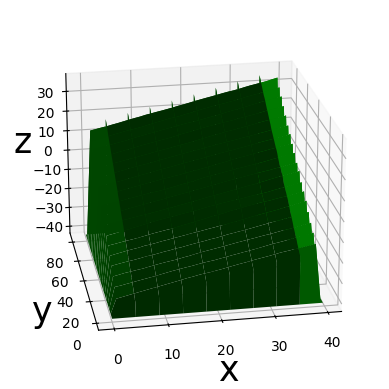

In [ ]:
# Display the surface here


# Set display parameters
fontsize = 25
linewidth = 2
xmaxtot = (nxtot-1)*dx; print (xmaxtot)
ymaxtot = (nytot-1)*dy; print (ymaxtot)
surf_ytot = np.linspace(0,ymaxtot,nytot); #print surf_ytot[1]-surf_ytot[0]; 
surf_xtot = np.linspace(0,xmaxtot,nxtot); #print surf_xtot[1]-surf_xtot[0]; 
surf_xgridtot, surf_ygridtot = np.meshgrid(surf_xtot,surf_ytot)
surf_ygridtot_flipped = np.flipud(surf_ygridtot)

# Display it
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(surf_xgridtot, surf_ygridtot_flipped, settemp4, rstride=4,cstride=4, color='g')
ax.view_init(azim=-100,elev=22)
ax.set_xlabel('x',fontsize=fontsize)
ax.set_ylabel('y',fontsize=fontsize)
ax.set_zlabel('z',fontsize=fontsize)

In [ ]:
# Save as stl (with possible vertical amplification)
# scale = 1/dx
scale = 1; print('scaling vertical by ', scale)
sls.numpy2stl(settemp4, stlfile, scale=scale, solid=False)
print('Complete')

scaling vertical by  1
Creating top mesh...
Complete


shape of settemp (75, 35)
iymid 38
z_of_x 35
[-5.00619584e-04  5.49393798e-01 -1.11125560e+01]
curvature_in_x -0.0010012391679146504
ixmid 18
[-2.53616517e-04 -6.25488122e-01  2.74888144e+01]
curvature_in_y -0.0005072330348733237
[  0.52952545 -10.97748451]
theta -27.90235853560891
R [[ 0.88374637  0.46796619]
 [-0.46796619  0.88374637]]
npts 35
shape (2, 35)
shape (2, 35)
[-0.64673732 27.78944514]
theta 32.89225660396148
R [[ 0.83969327 -0.54306097]
 [ 0.54306097  0.83969327]]
npts 75
shape (2, 75)
shape (2, 75)


Text(0.5, 0, 'y')

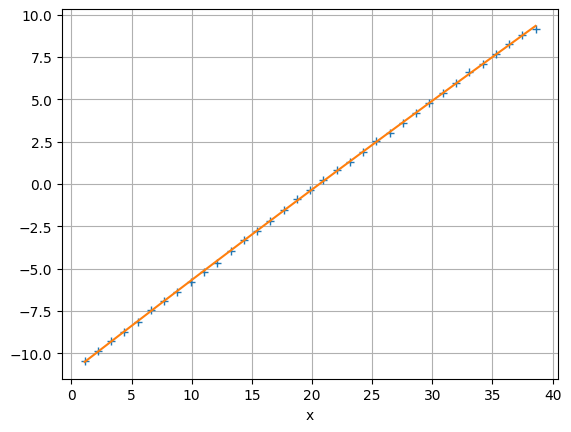

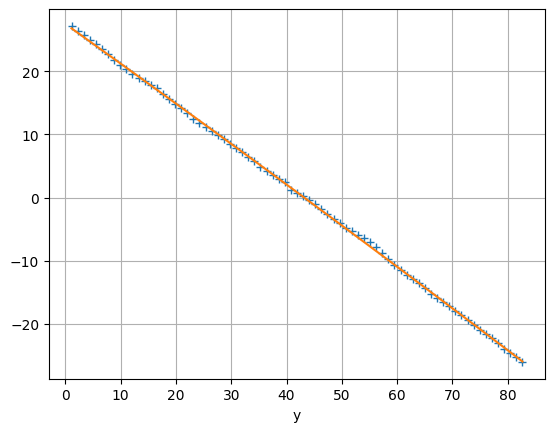

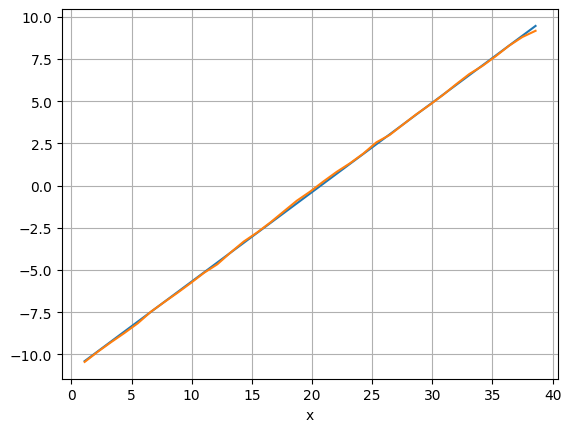

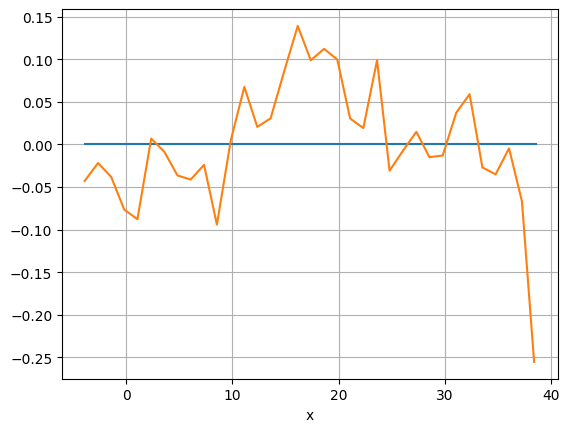

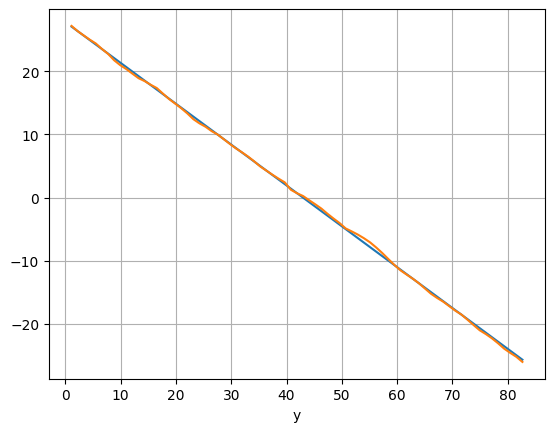

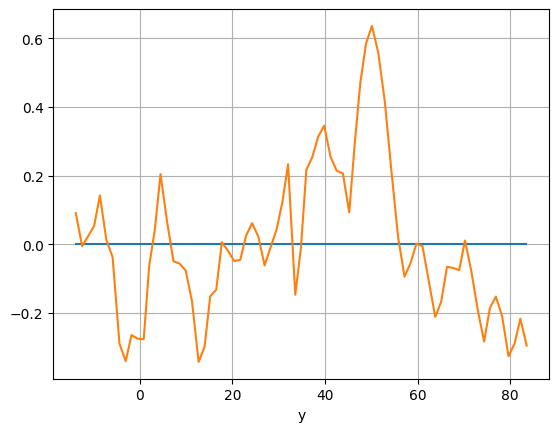

In [ ]:
# Curvature analysis
print('shape of settemp', np.shape(settemp))

# nx and ny are swapped above here
iymid = round(nx/2); print('iymid',iymid)
z_of_x = settemp[iymid,:]; print('z_of_x',len(z_of_x))
p = np.polyfit(surf_xtot[1:-1],z_of_x,2); print(p)
curvature_in_x = p[0]*2; print('curvature_in_x',curvature_in_x)
plt.figure()
plt.plot(surf_xtot[1:-1],z_of_x,'+')
plt.plot(surf_xtot[1:-1],np.polyval(p,surf_xtot[1:-1]))
plt.grid(True)
plt.xlabel('x')

ixmid = round(ny/2); print('ixmid',ixmid)
z_of_y = settemp[:,ixmid]
p = np.polyfit(surf_ytot[1:-1],z_of_y,2); print(p)
curvature_fit = p[0]*2; print('curvature_in_y',curvature_fit)
plt.figure()
plt.plot(surf_ytot[1:-1],z_of_y,'+')
plt.plot(surf_ytot[1:-1],np.polyval(p,surf_ytot[1:-1]))
plt.grid(True)
plt.xlabel('y')

# Straightening it out
vector_straight, vector_actual, new_vector_straight, new_vector_actual = ims.straighten_it_out(surf_xtot[1:-1],z_of_x)
plt.figure()
plt.plot(vector_straight[0,:],vector_straight[1,:])
plt.plot(vector_actual[0,:],vector_actual[1,:])
plt.grid(True)
plt.xlabel('x')
plt.figure()
plt.plot(new_vector_straight[0,:],new_vector_straight[1,:])
plt.plot(new_vector_actual[0,:],new_vector_actual[1,:])
plt.grid(True)
plt.xlabel('x')

vector_straight, vector_actual, new_vector_straight, new_vector_actual = ims.straighten_it_out(surf_ytot[1:-1],z_of_y)
plt.figure()
plt.plot(vector_straight[0,:],vector_straight[1,:])
plt.plot(vector_actual[0,:],vector_actual[1,:])
plt.grid(True)
plt.xlabel('y')
plt.figure()
plt.plot(new_vector_straight[0,:],new_vector_straight[1,:])
plt.plot(new_vector_actual[0,:],new_vector_actual[1,:])
plt.grid(True)
plt.xlabel('y')